In [ ]:

!pip -q install kagglehub tensorflow scikit-learn matplotlib pillow
print("PlantCare AI setup completed!")


PlantCare AI setup completed!


In [ ]:

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "abdallahalidev/plantvillage-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset path:", dataset_path)
print("Files and folders:", os.listdir(dataset_path))


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/plantvillage-dataset
Files and folders: ['plantvillage dataset']


In [ ]:

import os

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

    if level >= 2:
        dirs[:] = []


plantvillage-dataset/
  plantvillage dataset/
    segmented/
    grayscale/
    color/


In [ ]:

import os

dataset_path = "/kaggle/input/plantvillage-dataset"
base_path = os.path.join(dataset_path, "plantvillage dataset")
color_path = os.path.join(base_path, "color")

print("Dataset exists:", os.path.exists(color_path))

classes = sorted(os.listdir(color_path))

print("\nTotal classes:", len(classes))
print("\nTomato classes:")

tomato_classes = [c for c in classes if "tomato" in c.lower()]

for i, class_name in enumerate(tomato_classes, 1):
    folder = os.path.join(color_path, class_name)
    count = sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    print(f"{i}. {class_name}: {count} images")


Dataset exists: True

Total classes: 38

Tomato classes:
1. Tomato___Bacterial_spot: 2127 images
2. Tomato___Early_blight: 1000 images
3. Tomato___Late_blight: 1909 images
4. Tomato___Leaf_Mold: 952 images
5. Tomato___Septoria_leaf_spot: 1771 images
6. Tomato___Spider_mites Two-spotted_spider_mite: 1676 images
7. Tomato___Target_Spot: 1404 images
8. Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357 images
9. Tomato___Tomato_mosaic_virus: 373 images
10. Tomato___healthy: 1591 images


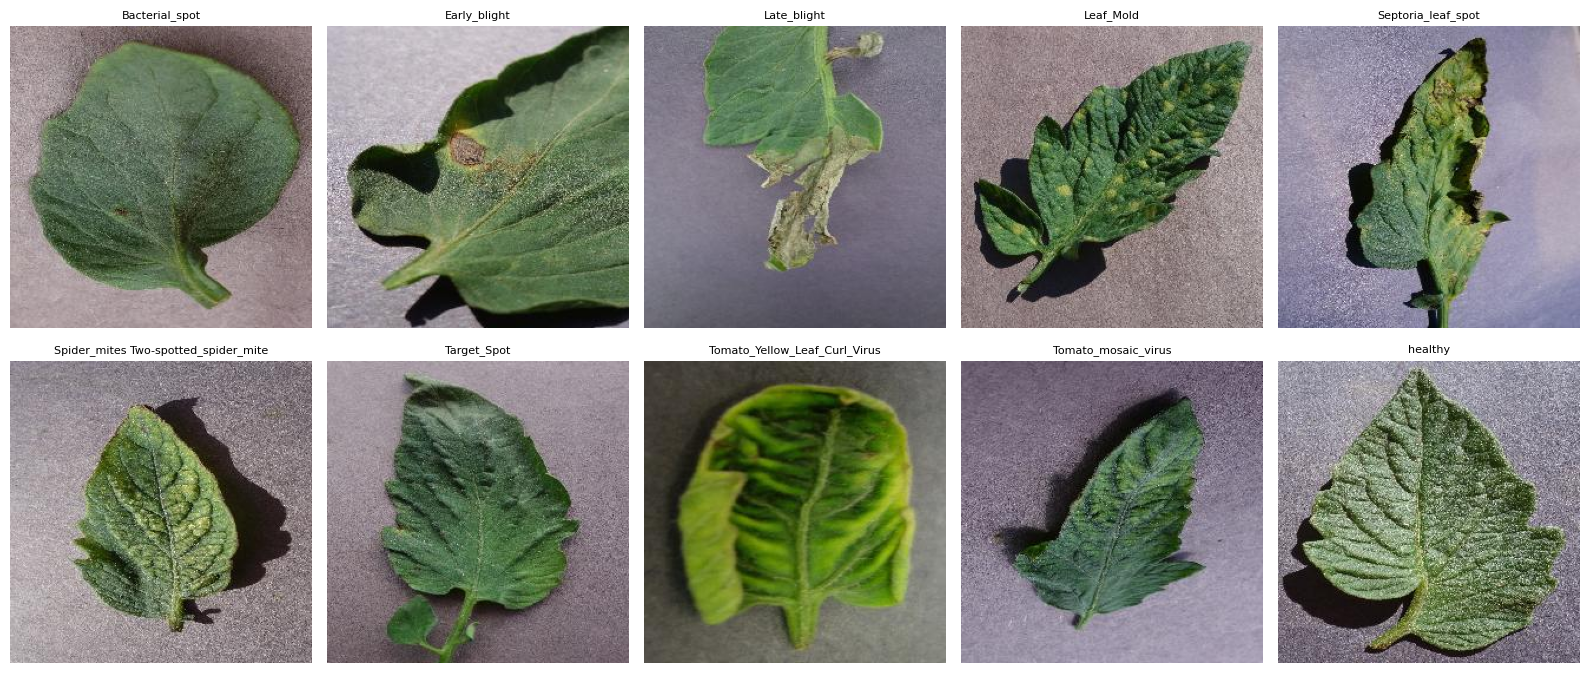

In [ ]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

selected_classes = tomato_classes

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

for ax, class_name in zip(axes, selected_classes):
    folder = os.path.join(color_path, class_name)

    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_file = random.choice(image_files)
    image_path = os.path.join(folder, image_file)

    img = Image.open(image_path).convert("RGB")

    ax.imshow(img)
    ax.set_title(class_name.replace("Tomato___", ""), fontsize=8)
    ax.axis("off")
-
plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training data (80%)
train_ds = keras.utils.image_dataset_from_directory(
    color_path,
    labels="inferred",
    label_mode="int",
    class_names=tomato_classes,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Split the remaining 20% into validation and test sets
remaining_ds = keras.utils.image_dataset_from_directory(
    color_path,
    labels="inferred",
    label_mode="int",
    class_names=tomato_classes,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

val_batches = tf.data.experimental.cardinality(remaining_ds).numpy()
test_ds = remaining_ds.take(val_batches // 2)
val_ds = remaining_ds.skip(val_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nClasses:", class_names)
print("Number of classes:", len(class_names))
print("Dataset preparation completed!")


Found 18160 files belonging to 10 classes.
Using 14528 files for training.
Found 18160 files belonging to 10 classes.
Using 3632 files for validation.

Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Number of classes: 10
Dataset preparation completed!


In [ ]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Pretrained model without its original classification head
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)
x = preprocess_input(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
454/454 ━━━━━━━━━━━━━━━━━━━━ 430s 941ms/step - accuracy: 0.7585 - loss: 0.7504 - val_accuracy: 0.8733 - val_loss: 0.4281
Epoch 2/5
454/454 ━━━━━━━━━━━━━━━━━━━━ 426s 939ms/step - accuracy: 0.8665 - loss: 0.4196 - val_accuracy: 0.8833 - val_loss: 0.3702
Epoch 3/5
454/454 ━━━━━━━━━━━━━━━━━━━━ 432s 916ms/step - accuracy: 0.8859 - loss: 0.3514 - val_accuracy: 0.9010 - val_loss: 0.3216
Epoch 4/5
454/454 ━━━━━━━━━━━━━━━━━━━━ 445s 921ms/step - accuracy: 0.8984 - loss: 0.3111 - val_accuracy: 0.9032 - val_loss: 0.3095
Epoch 5/5
454/454 ━━━━━━━━━━━━━━━━━━━━ 425s 935ms/step - accuracy: 0.9026 - loss: 0.2894 - val_accuracy: 0.8993 - val_loss: 0.3046


In [ ]:

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


57/57 ━━━━━━━━━━━━━━━━━━━━ 45s 783ms/step - accuracy: 0.9041 - loss: 0.2891

Test Accuracy: 90.41%
Test Loss: 0.2891


In [ ]:

model.save("plantcare_ai_model.keras")
print("PlantCare AI model saved successfully!")


PlantCare AI model saved successfully!


Saving Tomato Leaf Disease Diagnostic Chart (1).png to Tomato Leaf Disease Diagnostic Chart (1).png


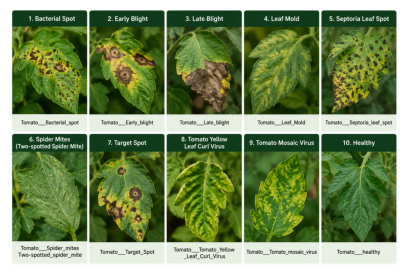

Predicted class: Tomato___Late_blight
Model confidence: 85.61%


In [14]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

image_array = np.array(img_resized, dtype=np.float32)
image_batch = np.expand_dims(image_array, axis=0)

predictions = model.predict(image_batch, verbose=0)[0]

predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2f}%")


In [13]:

import os
import random
import shutil
from google.colab import files

random.seed(42)

demo_folder = "/content/PlantCareAI_Demo_Images"
os.makedirs(demo_folder, exist_ok=True)

for class_name in class_names:
    source_folder = os.path.join(color_path, class_name)

    image_files = [
        f for f in os.listdir(source_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    selected_image = random.choice(image_files)

    source = os.path.join(source_folder, selected_image)

    # Save a separate image with its disease name
    safe_name = class_name.replace(" ", "_") + ".jpg"
    destination = os.path.join(demo_folder, safe_name)

    from PIL import Image
    with Image.open(source) as img:
        img.convert("RGB").save(destination, "JPEG")

    print("Saved:", safe_name)

zip_path = shutil.make_archive(
    "/content/PlantCareAI_Demo_Images",
    "zip",
    demo_folder
)

print("\nAll 10 demo images are ready!")
files.download(zip_path)


Saved: Tomato___Bacterial_spot.jpg
Saved: Tomato___Early_blight.jpg
Saved: Tomato___Late_blight.jpg
Saved: Tomato___Leaf_Mold.jpg
Saved: Tomato___Septoria_leaf_spot.jpg
Saved: Tomato___Spider_mites_Two-spotted_spider_mite.jpg
Saved: Tomato___Target_Spot.jpg
Saved: Tomato___Tomato_Yellow_Leaf_Curl_Virus.jpg
Saved: Tomato___Tomato_mosaic_virus.jpg
Saved: Tomato___healthy.jpg

All 10 demo images are ready!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

# Disease-wise care recommendation database

recommendations = {
    "Tomato___Bacterial_spot": {
        "disease": "Bacterial Spot",
        "solutions": [
            "Remove severely affected leaves carefully.",
            "Avoid overhead watering and wet foliage.",
            "Disinfect gardening tools and avoid handling wet plants.",
            "Consult a local agricultural expert if the disease spreads."
        ]
    },
    "Tomato___Early_blight": {
        "disease": "Early Blight",
        "solutions": [
            "Remove severely affected leaves.",
            "Keep foliage dry and improve air circulation.",
            "Use mulch to reduce soil splash onto leaves.",
            "Ask an agricultural expert about suitable disease management."
        ]
    },
    "Tomato___Late_blight": {
        "disease": "Late Blight",
        "solutions": [
            "Isolate affected plants where practical.",
            "Avoid overhead watering and prolonged leaf wetness.",
            "Remove severely infected plant material safely.",
            "Seek prompt local agricultural advice because this disease can spread rapidly."
        ]
    },
    "Tomato___Leaf_Mold": {
        "disease": "Leaf Mold",
        "solutions": [
            "Improve ventilation around plants.",
            "Avoid excess humidity and prolonged leaf wetness.",
            "Remove heavily affected leaves carefully.",
            "Use locally recommended disease management practices."
        ]
    },
    "Tomato___Septoria_leaf_spot": {
        "disease": "Septoria Leaf Spot",
        "solutions": [
            "Remove affected lower leaves carefully.",
            "Use mulch to limit soil splash.",
            "Avoid handling plants when foliage is wet.",
            "Ask an agricultural expert about suitable management options."
        ]
    },
    "Tomato___Spider_mites Two-spotted_spider_mite": {
        "disease": "Two-Spotted Spider Mites",
        "solutions": [
            "Inspect leaf undersides for mites and webbing.",
            "Remove heavily infested leaves when appropriate.",
            "Protect beneficial insects and avoid unnecessary broad-spectrum pesticides.",
            "Seek advice on suitable mite management if infestation persists."
        ]
    },
    "Tomato___Target_Spot": {
        "disease": "Target Spot",
        "solutions": [
            "Remove severely affected leaves.",
            "Improve airflow between plants.",
            "Avoid prolonged leaf wetness.",
            "Confirm the diagnosis before applying any treatment."
        ]
    },
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": {
        "disease": "Tomato Yellow Leaf Curl Virus",
        "solutions": [
            "Inspect plants for whiteflies, which can transmit the virus.",
            "Remove infected plants where recommended by local agricultural guidance.",
            "Manage whiteflies using locally approved integrated pest management.",
            "Choose resistant varieties for future planting where available."
        ]
    },
    "Tomato___Tomato_mosaic_virus": {
        "disease": "Tomato Mosaic Virus",
        "solutions": [
            "Remove infected plants where appropriate to limit spread.",
            "Wash hands and disinfect tools after handling plants.",
            "Avoid tobacco contamination and follow good plant hygiene.",
            "Use certified seed and resistant varieties where available."
        ]
    },
    "Tomato___healthy": {
        "disease": "Healthy Tomato Leaf",
        "solutions": [
            "Continue balanced watering and appropriate nutrition.",
            "Monitor leaves regularly for changes.",
            "Maintain good airflow and plant hygiene.",
            "No disease-specific treatment is indicated by this prediction."
        ]
    }
}

print("Recommendation database loaded!")
print("Available categories:", len(recommendations))


Recommendation database loaded!
Available categories: 10


Saving Tomato___Bacterial_spot.jpg to Tomato___Bacterial_spot.jpg


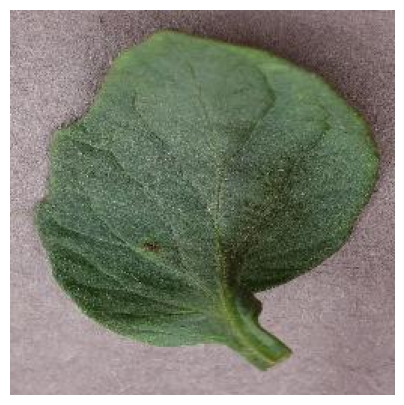

       PLANTCARE AI RESULTS
Predicted class: Bacterial_spot
Model confidence: 73.57%

Disease / Condition: Bacterial Spot

Recommended care:
1. Remove severely affected leaves carefully.
2. Avoid overhead watering and wet foliage.
3. Disinfect gardening tools and avoid handling wet plants.
4. Consult a local agricultural expert if the disease spreads.

Note: This is an AI prediction, not a confirmed diagnosis.


In [18]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
image_path = next(iter(uploaded))

img = Image.open(image_path).convert("RGB")
img_resized = img.resize((224, 224))

image_array = np.array(img_resized, dtype=np.float32)
image_batch = np.expand_dims(image_array, axis=0)

predictions = model.predict(image_batch, verbose=0)[0]
predicted_index = int(np.argmax(predictions))
predicted_class = class_names[predicted_index]
confidence = float(predictions[predicted_index]) * 100

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

print("=" * 45)
print("       PLANTCARE AI RESULTS")
print("=" * 45)
print("Predicted class:", predicted_class.replace("Tomato___", ""))
print(f"Model confidence: {confidence:.2f}%")

result = recommendations.get(predicted_class)

if result:
    print("\nDisease / Condition:", result["disease"])
    print("\nRecommended care:")
    for i, solution in enumerate(result["solutions"], 1):
        print(f"{i}. {solution}")

print("\nNote: This is an AI prediction, not a confirmed diagnosis.")


In [19]:

query = input("Search tomato disease (e.g. Early Blight): ").strip().lower()

matches = [
    (key, value)
    for key, value in recommendations.items()
    if query in key.lower() or query in value["disease"].lower()
]

if matches:
    for key, value in matches:
        print("\n🌿 Disease:", value["disease"])
        print("\nRecommended care:")

        for i, solution in enumerate(value["solutions"], 1):
            print(f"{i}. {solution}")
else:
    print("Disease not found. Please try another name.")


Search tomato disease (e.g. Early Blight): Early blight

🌿 Disease: Early Blight

Recommended care:
1. Remove severely affected leaves.
2. Keep foliage dry and improve air circulation.
3. Use mulch to reduce soil splash onto leaves.
4. Ask an agricultural expert about suitable disease management.


In [20]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

57/57 ━━━━━━━━━━━━━━━━━━━━ 45s 781ms/step - accuracy: 0.9024 - loss: 0.2950
Test Accuracy: 90.24%
Test Loss: 0.2950


In [21]:
model.save("plantcare_ai_model.keras")
print("PlantCare AI model saved successfully!")

PlantCare AI model saved successfully!


In [22]:
from google.colab import files
files.download("plantcare_ai_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>